# YOLO26: Rock, Paper, Scissors object detection

    **Learning outcomes:** distinguish classification and detection, inspect bounding-box
    labels, fine-tune YOLO26, evaluate held-out images, and display English predictions.

    This English edition uses Ultralytics YOLO26 instead of the original external
    PaddleYOLO workflow. Use the small `yolo26n.pt` model for the classroom. A pretrained
    COCO model does not know the three hand-gesture classes until it is fine-tuned.

    Prepare a **bounding-box detection** export, not a folder-only classification dataset.
    Run `02-object-detection\.venv\Scripts\python.exe scripts\fetch_rps.py` from the
    `english` directory, as the module README describes, to build the English Rock Paper
    Scissors dataset this notebook trains on.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", '1-epoch pipeline check via COURSE_EPOCHS')

Python: 3.12.15
torch: 2.14.1
Run mode: 1-epoch pipeline check via COURSE_EPOCHS


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
import json
MODULE = COURSE / "02-object-detection"
OUTPUT = MODULE / "outputs"
# Keep Ultralytics settings local to this edition, before importing the package.
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
import torch
from ultralytics import YOLO, settings
import ultralytics
import matplotlib.pyplot as plt
from detection_data import prepare_rps

OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
settings.update({"datasets_dir": str(MODULE / "data"),
                 "weights_dir": str(OUTPUT / "weights"),
                 "runs_dir": str(OUTPUT / "runs")})
torch.set_num_threads(2)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Ultralytics version:", ultralytics.__version__)
print("Device:", DEVICE)

Ultralytics version: 8.4.177
Device: cpu


## 1. Validate the dataset and label mapping

    Each annotation row contains `class_id x_center y_center width height`. Coordinates
    are normalized by image width and height. Class IDs must agree with `data.yaml`.
    We lowercase English names but preserve their ID order. Training, validation, and
    test splits must be separate; the validator rejects identical images across splits.

    `COURSE_SMOKE=1` explicitly switches to COCO8 to test the YOLO26 software pipeline.
    That diagnostic run is not a Rock Paper Scissors experiment or its evaluation.

In [4]:
if SMOKE:
    from detection_data import prepare_coco8
    DATA_CONFIG = str(prepare_coco8(MODULE / "data", OUTPUT / "coco8-smoke.yaml"))
    print("SMOKE TEST ONLY: COCO8 pipeline check; not hand-gesture training.")
else:
    DATA_CONFIG = OUTPUT / "rps-data.yaml"
    config, counts = prepare_rps(MODULE / "data" / "rock-paper-scissors", DATA_CONFIG)
    print("English class mapping:", dict(enumerate(config["names"])))
    print("Validated split sizes:", counts)
    DATA_CONFIG = str(DATA_CONFIG)

English class mapping: {0: 'rock', 1: 'paper', 2: 'scissors'}
Validated split sizes: {'train': {'images': 1485, 'boxes': 1973}, 'val': {'images': 50, 'boxes': 80}, 'test': {'images': 50, 'boxes': 80}}


## 2. Load pretrained weights and fine-tune

    YOLO26 supports training, validation, prediction, and export through the Ultralytics
    Python API. It also supports an end-to-end inference path. IoU, precision, recall,
    and mAP remain important; do not assume all historical YOLO post-processing details
    apply unchanged. See the linked official model guide for version-specific behavior.

    `workers=0` avoids notebook multiprocessing problems on Windows. The initial download
    needs internet. The smoke run uses a smaller image size and one epoch for speed. The
    classroom image size is 320 rather than 640 because one 640-pixel epoch measured over
    twenty minutes on this CPU, while a 320-pixel epoch measured about 205 seconds.

In [5]:
weights = OUTPUT / "weights" / "yolo26n.pt"
weights.parent.mkdir(parents=True, exist_ok=True)
model = YOLO(str(weights))
# Measured on this classroom CPU with two torch threads: one 320-pixel epoch takes about
# 205 seconds, while a 640-pixel epoch takes more than twenty minutes. The defaults below
# therefore keep a full run near thirty minutes. On a GPU, raise EPOCHS and IMGSZ.
# COURSE_EPOCHS shortens a pipeline check; the classroom default stays at ten epochs.
EPOCHS = int(os.environ.get("COURSE_EPOCHS", 1 if SMOKE else 10))
IMGSZ = 64 if SMOKE else 320
print(f"Epochs: {EPOCHS}; image size: {IMGSZ}; smoke: {SMOKE}")
results = model.train(data=DATA_CONFIG, epochs=EPOCHS, imgsz=IMGSZ,
                      batch=2 if SMOKE else 8, workers=0, device=DEVICE,
                      seed=42, deterministic=True,
                      project=str(OUTPUT / "runs"),
                      name="coco8-smoke" if SMOKE else "rps-yolo26n",
                      exist_ok=False, plots=True, cache=False)
best = Path(model.trainer.best)
if not best.exists():
    raise RuntimeError("Training did not produce a best checkpoint.")
print("Saved checkpoint:", best.name)

Epochs: 1; image size: 320; smoke: False


Ultralytics 8.4.177  Python-3.12.15 torch-2.14.1+cpu CPU (AMD Ryzen 5 5600H with Radeon Graphics)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\deep-learning-lab\english\02-object-detection\outputs\rps-data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=E:\deep-learning-lab\english\02-object-detection\outputs\weights\yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rps-yolo26n-2, nbs=64, nms=None, opse

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


...

                 paper         26         31      0.758      0.605       0.68      0.351


              scissors         18         22      0.215      0.455      0.237       0.11


Speed: 0.4ms preprocess, 22.0ms inference, 0.0ms loss, 1.2ms postprocess per image


Results saved to E:\deep-learning-lab\english\02-object-detection\outputs\runs\rps-yolo26n-2


Saved checkpoint: best.pt


## 3. Validate the trained checkpoint

    Select model settings with validation data. Use the independent test split only after
    those decisions. COCO8 smoke mode has no separate test experiment, so it reports
    validation diagnostics only. mAP50 and mAP50-95 use different IoU criteria.

In [6]:
trained = YOLO(str(best))
split = "val" if SMOKE else "test"
metrics = trained.val(data=DATA_CONFIG, split=split, device=DEVICE,
                      imgsz=IMGSZ, workers=0, batch=2 if SMOKE else 8,
                      project=str(OUTPUT / "runs"), name="evaluation")
print(f"{split} mAP50: {metrics.box.map50:.4f}")
print(f"{split} mAP50-95: {metrics.box.map:.4f}")
report = {"smoke_test": SMOKE, "evaluation_split": split,
          "dataset": "COCO8" if SMOKE else "Rock Paper Scissors",
          "map50": float(metrics.box.map50), "map50_95": float(metrics.box.map),
          "ultralytics_version": ultralytics.__version__}
(OUTPUT / ("smoke-metrics.json" if SMOKE else "rps-metrics.json")).write_text(
    json.dumps(report, indent=2), encoding="utf-8")

Ultralytics 8.4.177  Python-3.12.15 torch-2.14.1+cpu CPU (AMD Ryzen 5 5600H with Radeon Graphics)


YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 156.7±54.9 MB/s, size: 30.1 KB)


val: Scanning E:\deep-learning-lab\english\02-object-detection\data\rock-paper-scissors\test\labels... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 1.2Kit/s 0.0s

val: New cache created: E:\deep-learning-lab\english\02-object-detection\data\rock-paper-scissors\test\labels.cache


...

              scissors         23         24      0.541      0.689      0.639      0.265


Speed: 0.4ms preprocess, 23.7ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to E:\deep-learning-lab\english\02-object-detection\outputs\runs\evaluation-5


test mAP50: 0.5927
test mAP50-95: 0.2839


191

## 4. Draw predictions with English labels

Class: scissors; confidence: 0.293


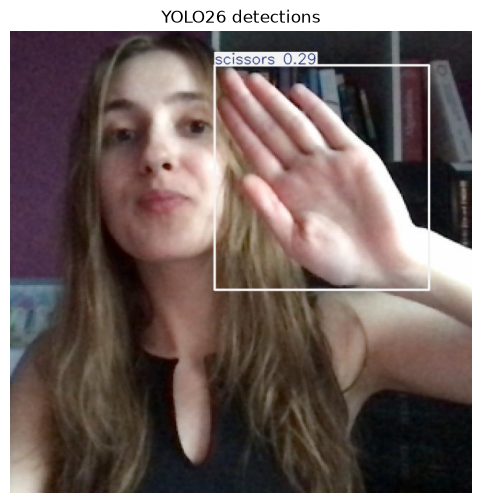

In [7]:
if SMOKE:
    from ultralytics.utils import ASSETS
    sample = ASSETS / "bus.jpg"
else:
    directory = MODULE / "data" / "rock-paper-scissors" / "test" / "images"
    sample = next(p for p in directory.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
prediction = trained.predict(source=str(sample), conf=0.25, device=DEVICE,
                              imgsz=IMGSZ, verbose=False)[0]
for box in prediction.boxes:
    print(f"Class: {prediction.names[int(box.cls.item())]}; confidence: {float(box.conf.item()):.3f}")
plt.figure(figsize=(8, 6))
plt.imshow(prediction.plot()[:, :, ::-1])
plt.title("YOLO26 detections" if not SMOKE else "COCO8 diagnostic predictions")
plt.axis("off")
plt.show()

## Exercises and optional export

    Inspect missed objects and false positives. Compare two confidence thresholds without
    retraining. Compare nano and small models using the same splits. Inspect the exported
    dataset for near-duplicate photos or the same participant appearing across splits;
    exact-byte duplicate checks alone cannot detect all leakage.

    Export is optional: `trained.export(format="onnx")`. It may install additional export
    dependencies; first verify numerical agreement with the original model.

    Sources: [YOLO26](https://docs.ultralytics.com/models/yolo26/),
    [training API](https://docs.ultralytics.com/modes/train/),
    [Rock Paper Scissors detection dataset](https://universe.roboflow.com/roboflow-58fyf/rock-paper-scissors-sxsw)
    through its [CC BY 4.0 mirror](https://huggingface.co/datasets/Xuban/rock-paper-scissors-roboflow).